<a href="https://colab.research.google.com/github/sofilukash/analysis_of_cyber_incidents_using_ml/blob/main/svm_iot_network_attacks_lab3.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Лабораторна робота 3
## Метод опорних векторів (SVM) в системах машинного навчання

**Мета:** реалізувати метод опорних векторів для виявлення мережевих атак на IoT-пристрої, оцінити точність моделі та дослідити фактори, від яких вона залежить.

**Завдання:** реалізувати алгоритм SVM на одному з датасетів Kaggle (розділ *security*), оцінити точність та фактори, що на неї впливають.

**Датасет:** Network IoT Dataset ([Kaggle: amineipad/ioittt](https://www.kaggle.com/datasets/amineipad/ioittt)) — записи мережевих з'єднань IoT-середовища. Бінарна класифікація: `label = 0` — нормальний трафік, `label = 1` — атака.

**План роботи:**
1. Завантаження даних
2. Первинний аналіз даних
3. Підготовка даних (очищення, кодування, масштабування, розділення на train/test)
4. Базова модель SVM
5. Дослідження факторів впливу на точність: масштабування, ядро, параметр `C`, параметр `gamma`, розмір вибірки, набір ознак, баланс класів
6. Підбір гіперпараметрів (`GridSearchCV`)
7. Фінальна модель та оцінка якості
8. Загальні висновки

## 0. Імпорт бібліотек

In [20]:
import os, glob, time, warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.model_selection import train_test_split, GridSearchCV, StratifiedKFold
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.svm import SVC, LinearSVC
from sklearn.metrics import (accuracy_score, precision_score, recall_score, f1_score,
                             roc_auc_score, ConfusionMatrixDisplay, classification_report)

warnings.filterwarnings("ignore")
RANDOM_STATE = 42
plt.rcParams.update({"figure.dpi": 100, "axes.grid": True, "grid.alpha": 0.3})

## 1. Завантаження даних
Файл береться з поточної папки; якщо його там немає — завантажується з Kaggle через `kagglehub`; якщо й це не вдалося — з'явиться вікно для ручного завантаження CSV.

In [2]:
FILE_NAME = "train_test_network.csv"

def find_dataset():
    if os.path.exists(FILE_NAME):
        return FILE_NAME
    try:
        try:
            import kagglehub
        except ImportError:
            import subprocess, sys
            subprocess.check_call([sys.executable, "-m", "pip", "install", "-q", "kagglehub"])
            import kagglehub
        folder = kagglehub.dataset_download("amineipad/ioittt")
        csv_files = glob.glob(os.path.join(folder, "**", "*.csv"), recursive=True)
        csv_files.sort(key=lambda p: os.path.basename(p) != FILE_NAME)  # потрібний файл — першим
        if csv_files:
            return csv_files[0]
    except Exception as e:
        print("Автозавантаження з Kaggle не вдалося:", e)
    from google.colab import files
    print(f"Завантажте файл {FILE_NAME} вручну:")
    return next(iter(files.upload()))

df = pd.read_csv(find_dataset())
print("Датасет завантажено:", df.shape)

100%|██████████| 1.71M/1.71M [00:00<00:00, 2.96MB/s]

Extracting files...


Датасет завантажено: (211043, 44)


## 2. Первинний аналіз даних
Дивимось на розмір таблиці, пропуски, дублікати та розподіл класів.

In [3]:
print("Розмір таблиці:", df.shape)
print("Пропусків (NaN):", int(df.isna().sum().sum()))
print("Повних дублікатів:", int(df.duplicated().sum()))

cat_all = df.select_dtypes(exclude="number").columns
dash = (df[cat_all] == "-").mean().sort_values(ascending=False)
print("\nЧастка значень '-' (ознака не застосовна до з'єднання), топ-8 колонок:")
print(dash.round(3).head(8).to_string())

df.head()

Розмір таблиці: (211043, 44)
Пропусків (NaN): 0
Повних дублікатів: 20569

Частка значень '-' (ознака не застосовна до з'єднання), топ-8 колонок:
ssl_subject             1.000
ssl_issuer              1.000
http_orig_mime_types    1.000
weird_addl              0.999
http_resp_mime_types    0.999
http_user_agent         0.999
http_method             0.999
http_uri                0.999


,src_ip,src_port,dst_ip,dst_port,proto,service,duration,src_bytes,dst_bytes,conn_state,...,http_response_body_len,http_status_code,http_user_agent,http_orig_mime_types,http_resp_mime_types,weird_name,weird_addl,weird_notice,label,type
0,192.168.1.37,4444,192.168.1.193,49178,tcp,-,290.371539,101568,2592,OTH,...,0,0,-,-,-,-,-,-,1,backdoor
1,192.168.1.193,49180,192.168.1.37,8080,tcp,-,0.000102,0,0,REJ,...,0,0,-,-,-,-,-,-,1,backdoor
2,192.168.1.193,49180,192.168.1.37,8080,tcp,-,0.000148,0,0,REJ,...,0,0,-,-,-,-,-,-,1,backdoor
3,192.168.1.193,49180,192.168.1.37,8080,tcp,-,0.000113,0,0,REJ,...,0,0,-,-,-,-,-,-,1,backdoor
4,192.168.1.193,49180,192.168.1.37,8080,tcp,-,0.000130,0,0,REJ,...,0,0,-,-,-,-,-,-,1,backdoor


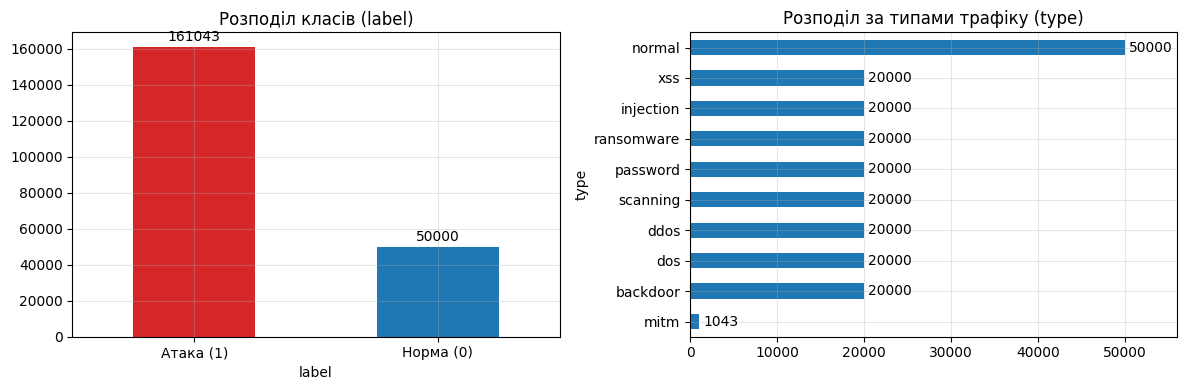

In [4]:
fig, ax = plt.subplots(1, 2, figsize=(12, 4))

df["label"].map({0: "Норма (0)", 1: "Атака (1)"}).value_counts().plot.bar(ax=ax[0], rot=0, color=["tab:red", "tab:blue"])
ax[0].set_title("Розподіл класів (label)")
ax[0].bar_label(ax[0].containers[0], padding=2)

df["type"].value_counts().sort_values().plot.barh(ax=ax[1], color="tab:blue")
ax[1].set_title("Розподіл за типами трафіку (type)")
ax[1].bar_label(ax[1].containers[0], padding=3); ax[1].margins(x=0.12)

plt.tight_layout(); plt.show()

**Висновок.** Датасет містить 211 043 записи та 44 ознаки, пропусків (NaN) немає, але в категоріальних колонках відсутні значення закодовано символом «-» (HTTP- та SSL-поля майже завжди порожні). Класи незбалансовані: атак ≈ 76% (161 043), норми — 50 000; атаки поділяються на 9 типів, найменший із яких — mitm (1 043 записи). Також є 20 569 повних дублікатів (≈ 10%), які потрібно прибрати до розділення на train/test.

## 3. Підготовка даних
Етапи: видалення колонок, що «підказують» відповідь або не несуть узагальнюваної інформації → видалення дублікатів → розділення на числові та категоріальні ознаки → розділення на навчальну та тестову вибірки (80/20 зі збереженням пропорцій класів).

In [5]:
# 1) type — це тип атаки, з якого прямо випливає label (витік мітки) → не можна використовувати як ознаку.
#    Зберігаємо окремо, щоб потім проаналізувати помилки за типами атак.
attack_type = df["type"]
data = df.drop(columns=["type"]).drop_duplicates()   # 2) дублікати: інакше однакові рядки потраплять і в train, і в test
attack_type = attack_type.loc[data.index]

# 3) IP-адреси — ідентифікатори конкретних машин лабораторного стенду, а не властивості трафіку;
#    решта — вільний текст з високою кількістю унікальних значень (запити, URI, user-agent, сертифікати)
DROP_COLS = ["src_ip", "dst_ip", "dns_query", "http_uri", "http_user_agent",
             "ssl_subject", "ssl_issuer", "weird_addl"]
data = data.drop(columns=DROP_COLS)

y = data["label"]
X = data.drop(columns="label")
cat_cols = X.select_dtypes(exclude="number").columns.tolist()
num_cols = X.select_dtypes(include="number").columns.tolist()

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, stratify=y, random_state=RANDOM_STATE)
type_test = attack_type.loc[X_test.index]

print(f"Після очищення: {len(data)} рядків, {X.shape[1]} ознак ({len(num_cols)} числових, {len(cat_cols)} категоріальних)")
print("Розподіл класів:", y.value_counts().to_dict())
print(f"Базовий рівень (завжди прогнозувати «атака»): accuracy = {max(y.mean(), 1 - y.mean()):.4f}")
print(f"Навчальна вибірка: {len(X_train)}, тестова: {len(X_test)}")

Після очищення: 190474 рядків, 34 ознак (16 числових, 18 категоріальних)
Розподіл класів: {1: 148434, 0: 42040}
Базовий рівень (завжди прогнозувати «атака»): accuracy = 0.7793
Навчальна вибірка: 152379, тестова: 38095


Допоміжні функції. Числові ознаки масштабуються `StandardScaler`, категоріальні кодуються `OneHotEncoder`. Попередня обробка вбудована в `Pipeline`, тому параметри масштабування обчислюються лише на навчальних даних. Ядровий SVM масштабується приблизно як O(n²…n³) за кількістю прикладів, тому в експериментах він навчається на стратифікованій підвибірці `N_TRAIN`, а оцінюється на всій тестовій вибірці.

In [6]:
N_TRAIN = 10_000   # розмір навчальної підвибірки для експериментів

def make_preprocessor(scale=True, numeric=None, categorical=None):
    numeric = num_cols if numeric is None else numeric
    categorical = cat_cols if categorical is None else categorical
    return ColumnTransformer([
        ("num", StandardScaler() if scale else "passthrough", numeric),
        ("cat", OneHotEncoder(handle_unknown="ignore"), categorical),
    ])

def subsample(n):
    if n >= len(X_train):
        return X_train, y_train
    Xs, _, ys, _ = train_test_split(X_train, y_train, train_size=n,
                                    stratify=y_train, random_state=RANDOM_STATE)
    return Xs, ys

def evaluate(model, n=N_TRAIN, scale=True, numeric=None, categorical=None):
    """Навчає Pipeline(preprocessing + model) на n прикладах, повертає метрики на тесті."""
    Xs, ys = subsample(n)
    pipe = Pipeline([("prep", make_preprocessor(scale, numeric, categorical)), ("svm", model)])
    t = time.time(); pipe.fit(Xs, ys); fit_time = time.time() - t
    pred = pipe.predict(X_test)
    metrics = {
        "accuracy":  accuracy_score(y_test, pred),
        "precision": precision_score(y_test, pred),
        "recall":    recall_score(y_test, pred),                 # частка виявлених атак
        "recall_norm": recall_score(y_test, pred, pos_label=0),  # частка правильно впізнаної норми
        "f1":        f1_score(y_test, pred),
        "fit_time_s": fit_time,
    }
    return metrics, pipe

def run_experiment(configs):
    rows = []
    for name, cfg in configs.items():
        m, _ = evaluate(**cfg)
        rows.append({"варіант": name, **m})
    return pd.DataFrame(rows).set_index("варіант")

## 4. Базова модель SVM
Класифікатор `SVC` з радіальним ядром (`rbf`) і параметрами за замовчуванням (`C=1`, `gamma='scale'`).

Навчання на 10000 прикладах, оцінка на 38095 тестових


,базова модель
accuracy,0.9858
precision,0.9919
recall,0.9899
recall_norm,0.9713
f1,0.9909
fit_time_s,0.8393


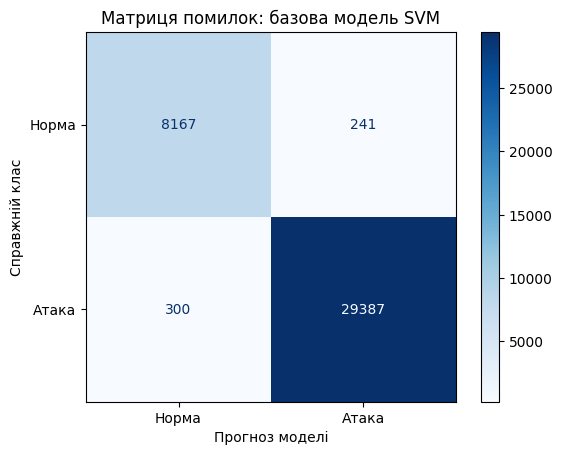

In [7]:
base_metrics, base_pipe = evaluate(SVC(kernel="rbf"), n=N_TRAIN)
print(f"Навчання на {N_TRAIN} прикладах, оцінка на {len(X_test)} тестових")
display(pd.Series(base_metrics).round(4).to_frame("базова модель"))

disp = ConfusionMatrixDisplay.from_estimator(base_pipe, X_test, y_test, display_labels=["Норма", "Атака"],
                                             cmap="Blues", values_format="d")
disp.ax_.grid(False); disp.ax_.set_title("Матриця помилок: базова модель SVM")
disp.ax_.set(xlabel="Прогноз моделі", ylabel="Справжній клас")
plt.show()

**Висновок.** Базова SVM із параметрами за замовчуванням, навчена лише на 10 000 прикладів, дає accuracy ≈ 0,986 проти 0,779 у тривіального класифікатора «завжди атака». Атаки виявляються краще (recall ≈ 0,990), ніж розпізнається норма (recall_norm ≈ 0,971), тобто основний тип помилок — хибні тривоги на нормальному трафіку. На незбалансованих даних accuracy потрібно розглядати разом із recall за класами.

## 5. Дослідження факторів, що впливають на точність
Змінюємо по одному фактору, решта параметрів — як у базовій моделі (`rbf`, `C=1`, `gamma='scale'`, масштабування, `N_TRAIN` прикладів). Підсумкові значення accuracy збираємо в `SUMMARY`.

In [8]:
SUMMARY = {}

def line_plot(series, xlabel, title, logx=True):
    ax = series.plot(marker="o", figsize=(6, 3.5), logx=logx)
    ax.set_xlabel(xlabel); ax.set_ylabel("accuracy"); ax.set_title(title)
    plt.tight_layout(); plt.show()

### 5.1. Масштабування ознак
SVM чутливий до масштабу ознак (відстані між об'єктами), а тут ознаки мають діапазони від 0 до мільйонів (байти, пакети, порти).

In [9]:
res_scale = run_experiment({
    "Без масштабування": dict(model=SVC(kernel="rbf"), scale=False),
    "StandardScaler":    dict(model=SVC(kernel="rbf"), scale=True),
})
SUMMARY["Масштабування"] = res_scale["accuracy"]
res_scale.round(4)

,accuracy,precision,recall,recall_norm,f1,fit_time_s
варіант,,,,,,
Без масштабування,0.7793,0.7793,1.0000,0.0001,0.8760,4.8289
StandardScaler,0.9858,0.9919,0.9899,0.9713,0.9909,0.5364


**Висновок.** Без масштабування модель повністю «вироджується»: accuracy = 0,779 збігається з базовим рівнем, а recall_norm ≈ 0 — усе класифікується як атака. Причина в тому, що ознаки з величезними діапазонами (байти, тривалість) домінують у відстанях між об'єктами. Зі `StandardScaler` accuracy зростає до 0,986, а навчання прискорюється приблизно у 8 разів (≈ 4,0 → 0,5 с). Масштабування — найвпливовіший фактор.

### 5.2. Тип ядра
Порівнюємо лінійне, поліноміальне, радіальне (RBF) та сигмоїдальне ядра.

,accuracy,precision,recall,recall_norm,f1,fit_time_s
варіант,,,,,,
linear,0.9852,0.9908,0.9902,0.9676,0.9905,0.6322
poly,0.9865,0.9921,0.9906,0.9721,0.9913,0.9178
rbf,0.9858,0.9919,0.9899,0.9713,0.9909,0.5619
sigmoid,0.9588,0.9715,0.9758,0.8988,0.9737,0.9905


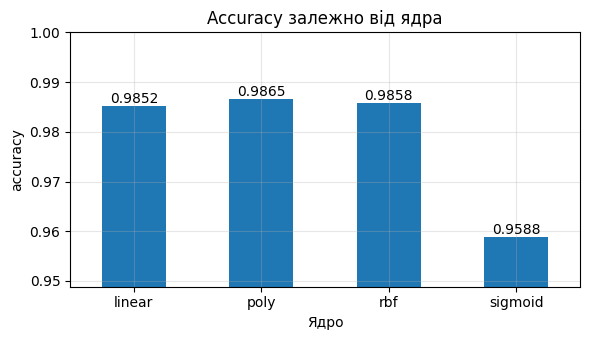

In [10]:
res_kernel = run_experiment({k: dict(model=SVC(kernel=k)) for k in ["linear", "poly", "rbf", "sigmoid"]})
SUMMARY["Тип ядра"] = res_kernel["accuracy"]
display(res_kernel.round(4))

ax = res_kernel["accuracy"].plot.bar(rot=0, figsize=(6, 3.5), color="tab:blue")
ax.set_ylim(res_kernel["accuracy"].min() - 0.01, 1); ax.set_xlabel("Ядро"); ax.set_ylabel("accuracy"); ax.set_title("Accuracy залежно від ядра")
ax.bar_label(ax.containers[0], fmt="%.4f"); plt.tight_layout(); plt.show()

**Висновок.** Лінійне, поліноміальне та RBF-ядра дають практично однакову точність (0,985–0,987): різниця лише в третьому знаку, тому віддавати перевагу якомусь одному за цими даними не можна, а сам факт свідчить, що класи майже лінійно роздільні. Сигмоїдальне ядро помітно гірше (0,959; recall_norm ≈ 0,899). Далі використовуємо RBF як найгнучкіше ядро з налаштовуваними параметрами.

### 5.3. Параметр регуляризації C
`C` задає штраф за помилки класифікації: мале `C` — широкий «коридор» і більше помилок на навчальних даних, велике `C` — суворіше відсікання помилок.

,accuracy,precision,recall,recall_norm,f1,fit_time_s
варіант,,,,,,
0.01,0.9085,0.9248,0.9608,0.7241,0.9424,3.4172
0.10,0.9788,0.9838,0.9892,0.9424,0.9865,1.3099
1.00,0.9858,0.9919,0.9899,0.9713,0.9909,0.7540
10.00,0.9889,0.9938,0.9919,0.9781,0.9929,0.3950
100.00,0.9930,0.9945,0.9966,0.9806,0.9955,0.4695
1000.00,0.9924,0.9947,0.9956,0.9812,0.9951,0.5593


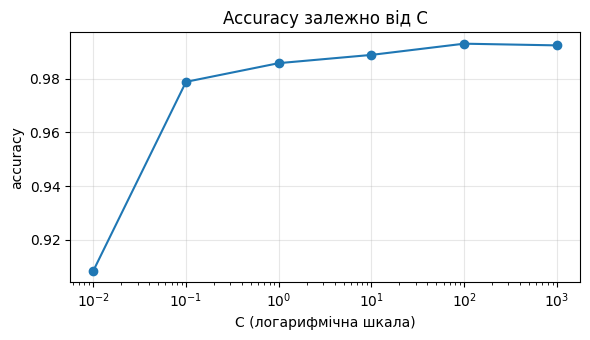

In [11]:
res_C = run_experiment({C: dict(model=SVC(kernel="rbf", C=C)) for C in [0.01, 0.1, 1, 10, 100, 1000]})
SUMMARY["Параметр C"] = res_C["accuracy"]
display(res_C.round(4))
line_plot(res_C["accuracy"].rename(index=float), "C (логарифмічна шкала)", "Accuracy залежно від C")

**Висновок.** При C = 0,01 модель надто «м'яка»: accuracy 0,909, recall_norm лише ≈ 0,724. Зі зростанням C точність швидко зростає (0,979 при C = 0,1; 0,986 при C = 1) і досягає максимуму ≈ 0,993 при C = 100; при C = 1000 вона вже не покращується (≈ 0,992) і виходить на плато. Для цих даних вигідніше штрафувати помилки суворіше, ніж за замовчуванням.

### 5.4. Параметр gamma (ядро RBF)
`gamma` визначає «радіус впливу» одного навчального прикладу: мале значення — гладка межа рішення, велике — дуже складна межа, схильна до перенавчання.

,accuracy,precision,recall,recall_norm,f1,fit_time_s
варіант,,,,,,
0.001,0.9542,0.9644,0.9773,0.8727,0.9708,2.0061
0.010,0.9833,0.9887,0.9899,0.9602,0.9893,0.8344
0.100,0.9884,0.9939,0.9912,0.9786,0.9925,0.7909
1.000,0.9917,0.9918,0.9976,0.9707,0.9947,0.5658
10.000,0.9866,0.9847,0.9982,0.9453,0.9914,1.5848


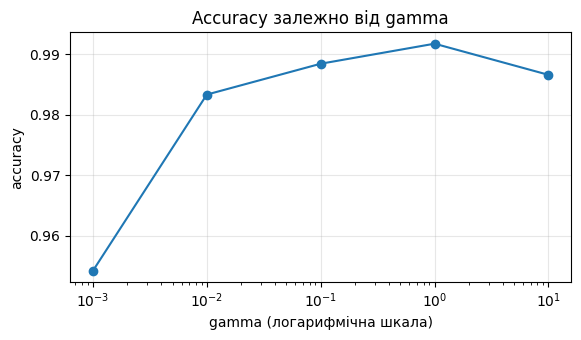

In [12]:
res_gamma = run_experiment({g: dict(model=SVC(kernel="rbf", gamma=g)) for g in [0.001, 0.01, 0.1, 1, 10]})
SUMMARY["Параметр gamma"] = res_gamma["accuracy"]
display(res_gamma.round(4))
line_plot(res_gamma["accuracy"].rename(index=float), "gamma (логарифмічна шкала)", "Accuracy залежно від gamma")

**Висновок.** Найгірша точність — при найменшому gamma = 0,001 (0,954): межа рішення надто гладка, модель недонавчена. Максимум — при gamma = 1 (≈ 0,992), але при gamma = 10 точність знову падає до ≈ 0,987, а recall_norm — до ≈ 0,945: надто складна межа підлаштовується під навчальні дані (перенавчання). Оптимум лежить у середині діапазону.

### 5.5. Розмір навчальної вибірки
Дивимось, як змінюються точність і час навчання при збільшенні кількості навчальних прикладів.

,accuracy,precision,recall,recall_norm,f1,fit_time_s
варіант,,,,,,
500,0.9771,0.9799,0.9909,0.9282,0.9854,0.0227
1000,0.9801,0.9839,0.9907,0.9427,0.9873,0.0331
2000,0.9806,0.9863,0.9889,0.9514,0.9876,0.0782
5000,0.9839,0.9902,0.9891,0.9655,0.9897,0.1934
10000,0.9858,0.9919,0.9899,0.9713,0.9909,0.5464
20000,0.9877,0.9920,0.9923,0.9716,0.9921,2.5714
40000,0.9885,0.9936,0.9916,0.9773,0.9926,6.4988


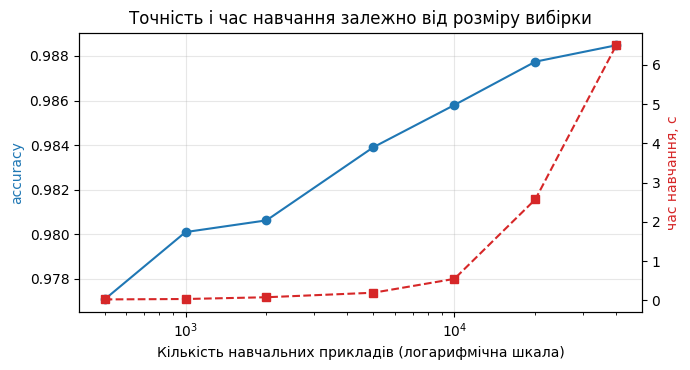

In [13]:
res_size = run_experiment({n: dict(model=SVC(kernel="rbf"), n=n) for n in [500, 1000, 2000, 5000, 10000, 20000, 40000]})
SUMMARY["Розмір вибірки"] = res_size["accuracy"]
display(res_size.round(4))

fig, ax = plt.subplots(figsize=(7, 3.8))
ax.semilogx(res_size.index.astype(float), res_size["accuracy"], "o-", color="tab:blue")
ax.set_xlabel("Кількість навчальних прикладів (логарифмічна шкала)"); ax.set_ylabel("accuracy", color="tab:blue")
ax2 = ax.twinx(); ax2.grid(False)
ax2.semilogx(res_size.index.astype(float), res_size["fit_time_s"], "s--", color="tab:red")
ax2.set_ylabel("час навчання, с", color="tab:red")
ax.set_title("Точність і час навчання залежно від розміру вибірки")
plt.tight_layout(); plt.show()

**Висновок.** Точність зростає з розміром вибірки: від 0,977 (500 прикладів) до 0,989 (40 000), але приріст швидко сповільнюється, тоді як час навчання зростає значно швидше — з ≈ 0,02 до ≈ 5,7 с (приблизно у 300 разів при збільшенні вибірки у 80 разів). Це типова властивість ядрового SVM, складність якого швидко зростає з кількістю прикладів, тому на великих даних використовують підвибірки або лінійні варіанти.

### 5.6. Набір ознак
Перевіряємо, яка частина ознак несе потрібну інформацію: усі ознаки; без номерів портів; лише числові; лише категоріальні.

In [14]:
no_ports = [c for c in num_cols if "port" not in c]
res_feat = run_experiment({
    "Усі ознаки":         dict(model=SVC(kernel="rbf")),
    "Без портів":         dict(model=SVC(kernel="rbf"), numeric=no_ports),
    "Лише числові":       dict(model=SVC(kernel="rbf"), categorical=[]),
    "Лише категоріальні": dict(model=SVC(kernel="rbf"), numeric=[]),
})
SUMMARY["Набір ознак"] = res_feat["accuracy"]
res_feat.round(4)

,accuracy,precision,recall,recall_norm,f1,fit_time_s
варіант,,,,,,
Усі ознаки,0.9858,0.9919,0.9899,0.9713,0.9909,0.5458
Без портів,0.9837,0.9896,0.9895,0.9632,0.9896,0.4799
Лише числові,0.8876,0.8799,0.9911,0.5222,0.9322,2.2507
Лише категоріальні,0.9399,0.9308,0.9970,0.7385,0.9628,0.8524


**Висновок.** Номери портів дають невеликий внесок: без них accuracy ≈ 0,984 (з ними 0,986), тож модель спирається переважно на характеристики самого трафіку. Лише числові ознаки дають 0,888 (recall_norm ≈ 0,522), лише категоріальні — 0,940; жоден набір окремо не достатній, найкращий результат дає поєднання протоколу, сервісу, стану з'єднання та кількісних характеристик.

### 5.7. Баланс класів
Атак у даних ≈ 78%. Перевіряємо, чи допомагає зважування класів `class_weight='balanced'`, яке збільшує штраф за помилки на рідшому класі (норма).

In [15]:
res_cw = run_experiment({
    "class_weight=None":       dict(model=SVC(kernel="rbf")),
    "class_weight='balanced'": dict(model=SVC(kernel="rbf", class_weight="balanced")),
})
SUMMARY["Баланс класів"] = res_cw["accuracy"]
res_cw.round(4)

,accuracy,precision,recall,recall_norm,f1,fit_time_s
варіант,,,,,,
class_weight=None,0.9858,0.9919,0.9899,0.9713,0.9909,0.5563
class_weight='balanced',0.9866,0.9941,0.9887,0.9792,0.9914,1.0467


**Висновок.** `class_weight='balanced'` майже не змінює загальну accuracy (0,9866 проти 0,9858), але перерозподіляє помилки: recall_norm зростає з ≈ 0,971 до ≈ 0,979, а recall атак трохи знижується (≈ 0,990 → 0,989). Тобто зважування покращує розпізнавання меншого класу (норми) майже без втрат — корисно, коли хибні тривоги дорогі. За впливом на загальну accuracy це найслабший фактор.

### 5.8. Зведення: який фактор впливає найсильніше
Для кожного фактора — мінімальна та максимальна accuracy серед перевірених значень; «розмах» показує чутливість моделі до цього фактора.

,min,max,розмах
Баланс класів,0.9858,0.9866,0.0008
Розмір вибірки,0.9771,0.9885,0.0114
Тип ядра,0.9588,0.9865,0.0277
Параметр gamma,0.9542,0.9917,0.0375
Параметр C,0.9085,0.9930,0.0845
Набір ознак,0.8876,0.9858,0.0981
Масштабування,0.7793,0.9858,0.2065


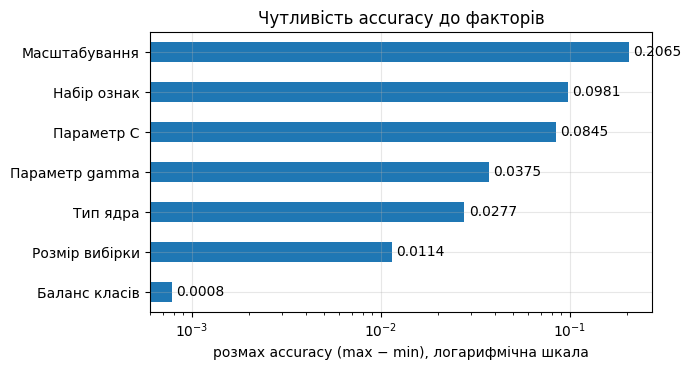

In [16]:
summary_df = pd.DataFrame({k: {"min": v.min(), "max": v.max(), "розмах": v.max() - v.min()}
                           for k, v in SUMMARY.items()}).T.sort_values("розмах")
display(summary_df.round(4))

ax = summary_df["розмах"].plot.barh(figsize=(7, 3.8), color="tab:blue")
ax.set_xscale("log"); ax.set_xlabel("розмах accuracy (max − min), логарифмічна шкала")
ax.set_title("Чутливість accuracy до факторів"); ax.bar_label(ax.containers[0], fmt="%.4f", padding=3)
plt.tight_layout(); plt.show()

**Висновок.** Найсильніше на точність впливають масштабування (розмах 0,207) і набір ознак (0,098), далі — параметр C (0,085), gamma (0,038) і тип ядра (0,028). Розмір вибірки та баланс класів змінюють accuracy менш ніж на 0,012. Тобто спершу потрібно правильно підготувати дані (масштаб, ознаки) і лише потім налаштовувати гіперпараметри. Порівняння орієнтовне: розмах залежить від діапазону значень, які ми перевіряли.

## 6. Підбір гіперпараметрів
Перебір `C` та `gamma` для ядра RBF за допомогою `GridSearchCV` (3-кратна стратифікована крос-валідація на навчальній підвибірці).

Час підбору: 71 с
Найкращі параметри: {'svm__C': 1000, 'svm__gamma': 0.01}
Accuracy на крос-валідації: 0.9922


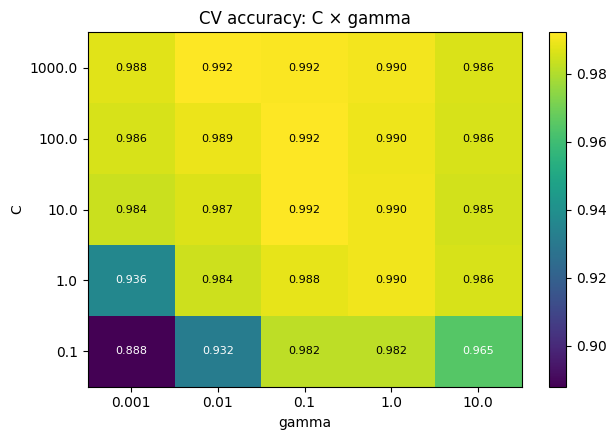

In [17]:
Xs, ys = subsample(N_TRAIN)
pipe = Pipeline([("prep", make_preprocessor()), ("svm", SVC(kernel="rbf"))])
param_grid = {"svm__C": [0.1, 1, 10, 100, 1000],
              "svm__gamma": [0.001, 0.01, 0.1, 1, 10]}

grid = GridSearchCV(pipe, param_grid, scoring="accuracy", n_jobs=-1,
                    cv=StratifiedKFold(3, shuffle=True, random_state=RANDOM_STATE))
t = time.time(); grid.fit(Xs, ys)
print(f"Час підбору: {time.time() - t:.0f} с")
print("Найкращі параметри:", grid.best_params_)
print(f"Accuracy на крос-валідації: {grid.best_score_:.4f}")

heat = (pd.DataFrame(grid.cv_results_)
        .pivot_table(index="param_svm__C", columns="param_svm__gamma", values="mean_test_score"))
fig, ax = plt.subplots(figsize=(6.5, 4.5))
im = ax.imshow(heat.values, cmap="viridis", aspect="auto", origin="lower")
ax.set_xticks(range(heat.shape[1]), heat.columns); ax.set_yticks(range(heat.shape[0]), heat.index)
ax.set_xlabel("gamma"); ax.set_ylabel("C"); ax.set_title("CV accuracy: C × gamma"); ax.grid(False)
for i in range(heat.shape[0]):
    for j in range(heat.shape[1]):
        v = heat.values[i, j]
        ax.text(j, i, f"{v:.3f}", ha="center", va="center", color="white" if v < heat.values.mean() else "black", fontsize=8)
plt.colorbar(im, ax=ax); plt.tight_layout(); plt.show()

**Висновок.** Найкраща комбінація — C = 1000, gamma = 0,01 (CV-accuracy ≈ 0,992). На теплокарті видно широке «плато» високої точності (≈ 0,99): що менший C, то більший gamma потрібен, і навпаки, а кілька комбінацій дають майже однаковий результат (наприклад, C = 10, gamma = 0,1 також ≈ 0,992), тому різниця між верхніми варіантами в межах шуму. Найгірші області — малі C і малі gamma (недонавчання). Оптимум лежить на межі сітки за C, але приріст там уже мізерний.

## 7. Фінальна модель та оцінка якості
Модель з найкращими параметрами навчається на більшій підвибірці (`N_FINAL`) і оцінюється на тестовій вибірці, яку модель не бачила. Окремо дивимось точність за типами атак та порівнюємо з лінійним SVM (`LinearSVC`), який масштабується на всю навчальну вибірку.

SVC(rbf, C=1000, gamma=0.01), навчання на 50000 прикладах, опорних векторів: 825
Accuracy: 0.9937   ROC-AUC: 0.9982

              precision    recall  f1-score   support

       Норма     0.9903    0.9812    0.9857      8408
       Атака     0.9947    0.9973    0.9960     29687

    accuracy                         0.9937     38095
   macro avg     0.9925    0.9892    0.9909     38095
weighted avg     0.9937    0.9937    0.9937     38095



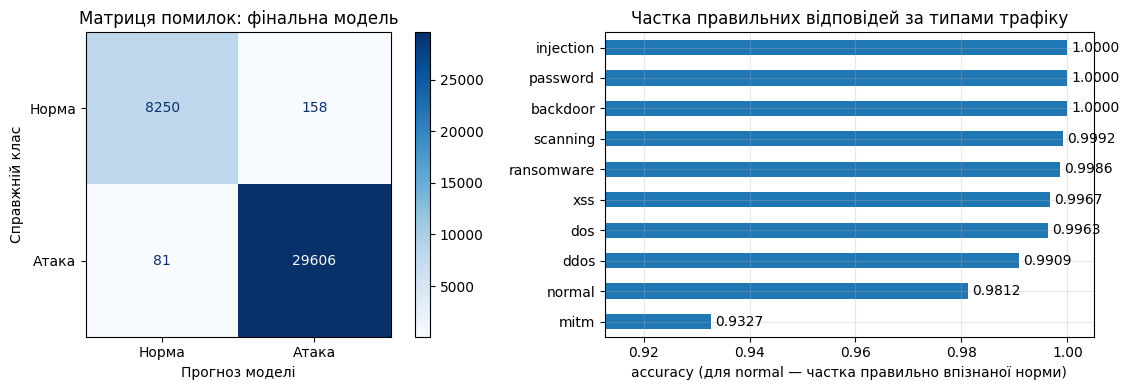

In [18]:
N_FINAL = 50_000
best_C, best_gamma = grid.best_params_["svm__C"], grid.best_params_["svm__gamma"]

final_metrics, final_pipe = evaluate(SVC(kernel="rbf", C=best_C, gamma=best_gamma), n=N_FINAL)
scores = final_pipe.decision_function(X_test)
pred = (scores > 0).astype(int)

print(f"SVC(rbf, C={best_C}, gamma={best_gamma}), навчання на {N_FINAL} прикладах, "
      f"опорних векторів: {final_pipe['svm'].n_support_.sum()}")
print(f"Accuracy: {accuracy_score(y_test, pred):.4f}   ROC-AUC: {roc_auc_score(y_test, scores):.4f}\n")
print(classification_report(y_test, pred, target_names=["Норма", "Атака"], digits=4))

fig, ax = plt.subplots(1, 2, figsize=(12, 4))
ConfusionMatrixDisplay.from_predictions(y_test, pred, display_labels=["Норма", "Атака"],
                                        cmap="Blues", values_format="d", ax=ax[0])
ax[0].grid(False); ax[0].set_title("Матриця помилок: фінальна модель")
ax[0].set(xlabel="Прогноз моделі", ylabel="Справжній клас")

per_type = (pd.DataFrame({"type": type_test.values, "ok": pred == y_test.values})
            .groupby("type")["ok"].mean().sort_values())
per_type.plot.barh(ax=ax[1], color="tab:blue"); ax[1].set_xlim(per_type.min() - 0.02, 1.005)
ax[1].set_title("Частка правильних відповідей за типами трафіку"); ax[1].set_xlabel("accuracy (для normal — частка правильно впізнаної норми)"); ax[1].set_ylabel(""); ax[1].bar_label(ax[1].containers[0], fmt="%.4f", padding=3)
plt.tight_layout(); plt.show()

**Висновок.** Фінальна модель досягла accuracy = 0,9937 і ROC-AUC ≈ 0,998 на тестових даних, яких не бачила під час навчання. Атаки виявляються у 99,7% випадків (пропущено 81 із 29 687), норма розпізнається у 98,1% (158 хибних тривог із 8 408). Моделі вистачило 825 опорних векторів із 50 000 прикладів (≈ 1,7%). Найгірше розпізнається mitm (≈ 93%) — найменший клас (≈ 0,5% даних), далі норма та ddos; injection, password і backdoor — без жодної помилки.

In [19]:
lin_metrics, _ = evaluate(LinearSVC(max_iter=5000), n=len(X_train))
comparison = pd.DataFrame({
    f"SVC rbf (C={best_C}, gamma={best_gamma}), {N_FINAL} прикл.": final_metrics,
    f"LinearSVC, усі {len(X_train)} прикл.": lin_metrics,
}).T
comparison.round(4)

,accuracy,precision,recall,recall_norm,f1,fit_time_s
"SVC rbf (C=1000, gamma=0.01), 50000 прикл.",0.9937,0.9947,0.9973,0.9812,0.9960,14.3152
"LinearSVC, усі 152379 прикл.",0.9854,0.9911,0.9901,0.9686,0.9906,11.1902


**Висновок.** Лінійний SVM, навчений на всій вибірці (152 тис. прикладів), дає accuracy ≈ 0,985, тобто на рівні базової RBF-моделі, навченої на 10 тис., але поступається налаштованій RBF (≈ 0,994): помилок приблизно у 2,3 раза більше (1,46% проти 0,63%). Час навчання порівнянний (≈ 8 с проти ≈ 11 с), при цьому `LinearSVC` значно краще масштабується на великі обсяги даних, ніж RBF-ядро (див. п. 5.5).

## 8. Загальні висновки
1. Реалізовано метод опорних векторів (`SVC` з RBF-ядром) для бінарної класифікації мережевого трафіку IoT (норма / атака) на Network IoT Dataset. Після очищення (≈ 190 тис. записів, 34 ознаки) фінальна модель має **accuracy = 0,9937** і **ROC-AUC ≈ 0,998** на тесті, тоді як базовий рівень «завжди атака» — 0,779.
2. **Підготовка даних критична.** Колонку `type` потрібно прибрати (витік мітки), дублікати — видалити, IP-адреси та текстові поля — відкинути. Без масштабування SVM не працює взагалі (accuracy = базовому рівню).
3. **Фактори впливу на точність** (за спаданням чутливості): масштабування → набір ознак → параметр `C` → параметр `gamma` → тип ядра → розмір вибірки → баланс класів. Параметри `C` і `gamma` залежні, тому їх підбирають разом (`GridSearchCV`): мале `C` або мале `gamma` дає недонавчання, надто велике `gamma` — перенавчання.
4. **Практичні висновки.** Ядровий SVM добре підходить для цієї задачі, але його час навчання швидко зростає з розміром вибірки, тому на великих даних використовують підвибірку або `LinearSVC`. Через незбалансованість класів оцінювати модель потрібно не лише за accuracy, а й за recall кожного класу та за типами атак.
5. **Обмеження.** Розділення на train/test випадкове, тому схожі записи однієї атаки можуть потрапити і в навчальну, і в тестову вибірку; на трафіку з іншої мережі або з іншого часу точність, імовірно, буде нижчою.